# Exercise 07.01. Data Preparation

In the exercises of week 7 we worked with penguin data sets and k-NN classification.

We decided to include 07.01 eventhough it is not part of the mandatory assignments, as this is where we prepare and explore the data for 07.02, which is the mandatory assignment from week 7.

## Explore the data:
The goal is to explore these datasets, identify differences, and use data visualization techniques to analyze their structure. 


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Import the data files
original = pd.read_csv("Assets/Exercise_07_data/original_penguins.csv")
knn = pd.read_csv("Assets/Exercise_07_data/penguins_knn.csv")
no_chin = pd.read_csv("Assets/Exercise_07_data/penguins_no_chinstraps.csv")

datasets = {"original": original, "knn": knn, "no_chinstraps": no_chin}


FileNotFoundError: [Errno 2] No such file or directory: '../Assets/Exercise_07_data/original_penguins.csv'

Shape of each file:

In [ ]:
print("Shape: (rows and collumns)")
print(f"original: {original.shape}" )
print(f"knn: {knn.shape}")
print(f"no chin: {no_chin.shape}")

Shape: (rows and collumns)
original: (344, 7)
knn: (344, 7)
no chin: (276, 7)


Head of each file (Collumn names):

In [ ]:
print("original:")
print(original.head(2))
print()

print("knn")
print(knn.head(2))
print()

print("no_chin")
print(no_chin.head(2))

original:
  species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
0  Adelie  Torgersen            39.1           18.7              181.0   
1  Adelie  Torgersen            39.5           17.4              186.0   

   body_mass_g     sex  
0       3750.0    Male  
1       3800.0  Female  

knn
  species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
0     NaN  Torgersen            39.1           18.7              181.0   
1  Adelie  Torgersen            39.5           17.4              186.0   

   body_mass_g     sex  
0       3750.0    Male  
1       3800.0  Female  

no_chin
  species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
0  Adelie  Torgersen            39.1           18.7              181.0   
1  Adelie  Torgersen            39.5           17.4              186.0   

   body_mass_g     sex  
0       3750.0    Male  
1       3800.0  Female  


Amount of N/a-values and data types:

In [ ]:
types_overview = pd.DataFrame({
    name: df.dtypes
    for name, df in datasets.items()
}).T

print("data types:")
types_overview


amount of n/a-values:


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
original,object,object,float64,float64,float64,float64,object
knn,object,object,float64,float64,float64,float64,object
no_chinstraps,object,object,float64,float64,float64,float64,object


In [ ]:

na_overview = pd.DataFrame({
    name: df.isna().sum()
    for name, df in datasets.items()
}).T


print("amount of n/a-values:")
na_overview


amount of n/a-values:


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
original,0,0,2,2,2,2,11
knn,102,0,2,2,2,2,11
no_chinstraps,0,0,2,2,2,2,11


In [ ]:
summary = pd.DataFrame({
    name: {
        "rows": df.shape[0],
        "columns": df.shape[1],
        "n_species": df["species"].nunique(), # NaN is excluded by default
        "species_values": ", ".join(df["species"].dropna().unique()),
        "missing_species": df["species"].isna().sum(),
        "total_missing_cells": df.isna().sum().sum(),
    }
    for name, df in datasets.items()
}).T          # transpose so datasets are rows

summary

,rows,columns,n_species,species_values,missing_species,total_missing_cells
original,344,7,3,"Adelie, Chinstrap, Gentoo",0,19
knn,344,7,3,"Adelie, Chinstrap, Gentoo",102,121
no_chinstraps,276,7,2,"Adelie, Gentoo",0,19


<h3> Compare the data sets:</h3>

Characteristics:
of the three data sets: original, knn and no_chin
* The 3 data files have same amount of columns (7) and matching collumn names and data types.
* Original and knn both have 344 rows, no chin 276

**no_chinstraps is the simplest** in terms of features, as it excludes all rows of chinstrap.
The result is a data set with only two species.

Missing data (na values):
* knn have na value in collumn *Species* on 102 rows
* no_chin does not have any *Species* data
* Other than that the amounts of missing data (na values) match, however not certain that the same rows miss the data among the 3 files: \
    island                0 \
    bill_length_mm        2 \
    bill_depth_mm         2 \
    flipper_length_mm     2 \
    body_mass_g           2 \
    sex                  11 

<h3>Visualize the datasets:</h3>



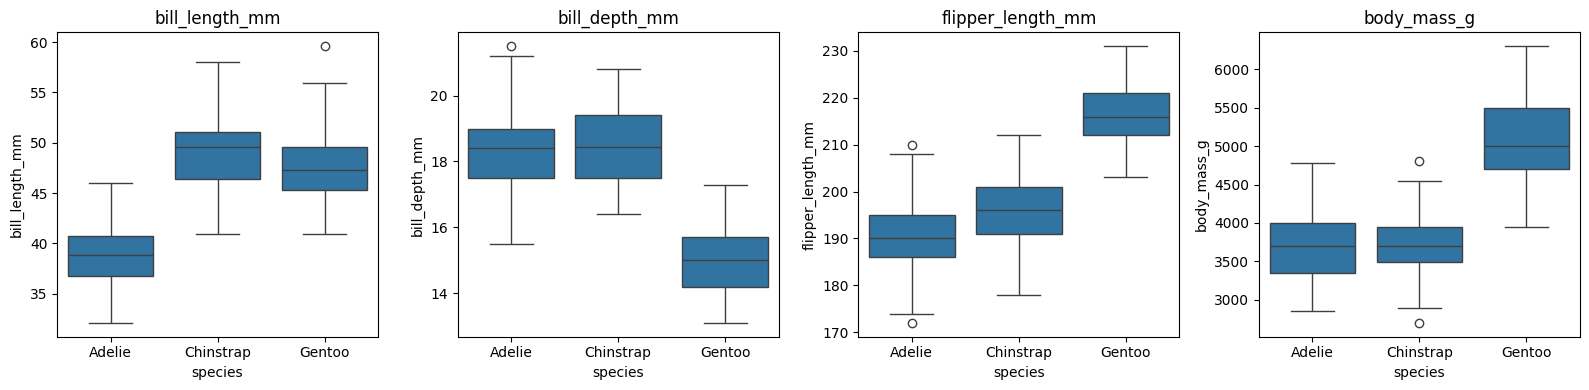

In [ ]:
import seaborn as sns

features = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

for ax, feat in zip(axes, features):
    sns.boxplot(data=original, x="species", y=feat, ax=ax)
    ax.set_title(feat)

plt.tight_layout()
plt.show()

<h3>Conclusions</h3>

The plots above show some overlaps between:
* Bill lenght:    Chinstrap and Gentoo
* Bill depth:     Adelie and Chinstrap (close to same avg)
* Flipper length: Adelie and Chinstrap (less overlap)
* Body mass:      Adelie and Chinstrap (close to same avg)

This indicate that it will be very difficult to seperate Adelie and Chinstrap on anything other than bill lenght.

Lets try to plot and visualize some of these problematic features: 
1. Body mass w. bill depth
2. bill depth w. flipper length


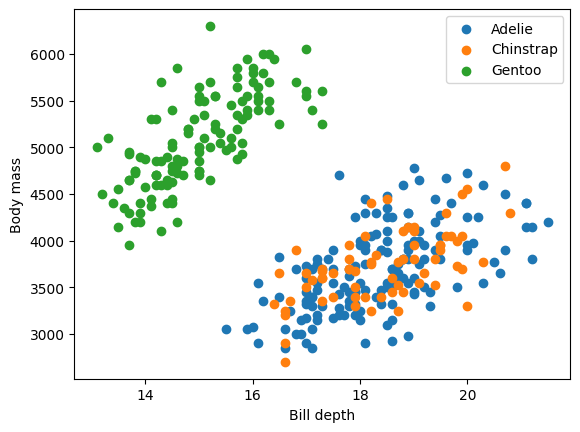

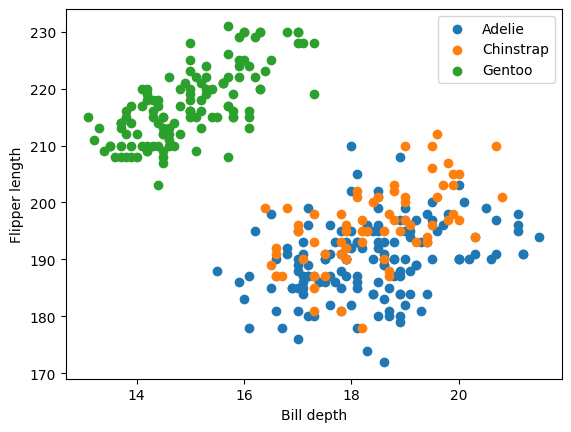

In [ ]:
for species, group in original.groupby("species"):
    plt.scatter(group["bill_depth_mm"], group["body_mass_g"], label=species)
plt.xlabel("Bill depth")
plt.ylabel("Body mass")
plt.legend()
plt.show()

for species, group in original.groupby("species"):
    plt.scatter(group["bill_depth_mm"], group["flipper_length_mm"], label=species)
plt.xlabel("Bill depth")
plt.ylabel("Flipper length")
plt.legend()
plt.show()


In stead we can use some other features to separate the species:
* Bill depth w. bill length
* Body mass w. bill length

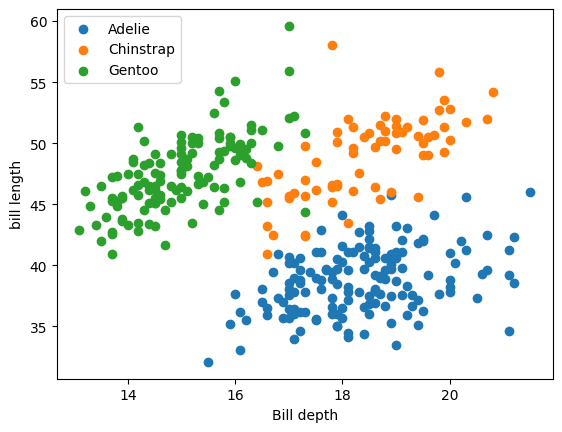

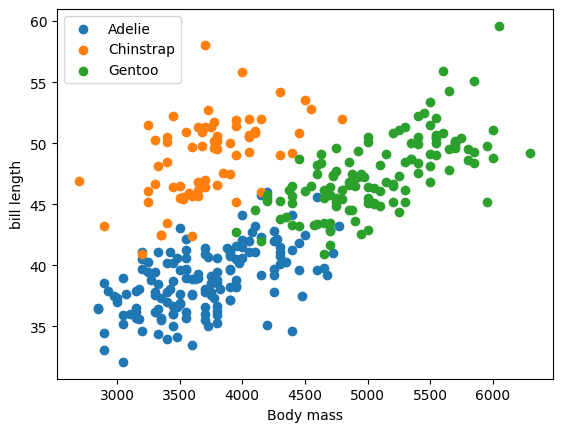

In [ ]:
for species, group in original.groupby("species"):
    plt.scatter(group["bill_depth_mm"], group["bill_length_mm"], label=species)
plt.xlabel("Bill depth")
plt.ylabel("bill length")
plt.legend()
plt.show()

for species, group in original.groupby("species"):
    plt.scatter(group["body_mass_g"], group["bill_length_mm"], label=species)
plt.xlabel("Body mass")
plt.ylabel("bill length")
plt.legend()
plt.show()

<h2>Exercise 07.02. </h2> 

*The Closest Neighbors Are the Trustful Ones!* 

(Mandatory for assignment 1)

Task:
* use the k-Nearest Neighbors (k-NN) algorithm to classify missing species data from the penguins_knn.csv dataset. 
* Leveraging different physical attributes such as bill length, bill depth, flipper length, and body mass to develop a routine to predict the missing species entries.

**Load the dataset.**

*  Load the penguins_knn.csv dataset into a Pandas DataFrame .

In [ ]:
import pandas as pd

original = pd.read_csv("../Assets/Exercise_07_data/original_penguins.csv")
knn = pd.read_csv("../Assets/Exercise_07_data/penguins_knn.csv")
no_chin = pd.read_csv("../Assets/Exercise_07_data/penguins_no_chinstraps.csv")



**Classify missing species using k-NN.**

Strategy:
* Training set: rows in knn with a species
* Rows to predict: rows in knn without a species

* Checked with the original file 

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score

labeled   = knn[knn["species"].notna()] # Training
unlabeled = knn[knn["species"].isna()] # Target

features = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]

def knn_predict(cols, k): #k must be uneven (we can not have a draw)
    train  = labeled.dropna(subset=cols) #takes the specified feature and drops na values.
    target = unlabeled.dropna(subset=cols)
    model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k)) #standard skaler (0-1), as bodymass would dominate the mm-values
    model.fit(train[cols], train["species"])

    return pd.Series(model.predict(target[cols]), index=target.index)

def evaluate(pred):
    true = original.loc[pred.index, "species"]
    return accuracy_score(true, pred)

**1. Which attribute provided the best classification results when used individually?** 

The best result when using a single attribute is the flipper_length_mm, which gives an accuracy of 0.76, 
marginally better than bill_length and bill_depth (both 0.75).


In [ ]:
rows = []
for name, cols in [(f, [f]) for f in features]:
    pred = knn_predict(cols, k=5)
    rows.append({"attributes": name,
                 "predicted": len(pred),
                 "accuracy": round(evaluate(pred), 2)})
    
pd.DataFrame(rows)

,attributes,predicted,accuracy
0,bill_length_mm,101,0.75
1,bill_depth_mm,101,0.75
2,flipper_length_mm,101,0.76
3,body_mass_g,101,0.63


This is also indicated by these plots, which show how each specie have overlap in terms of the individual attributes:

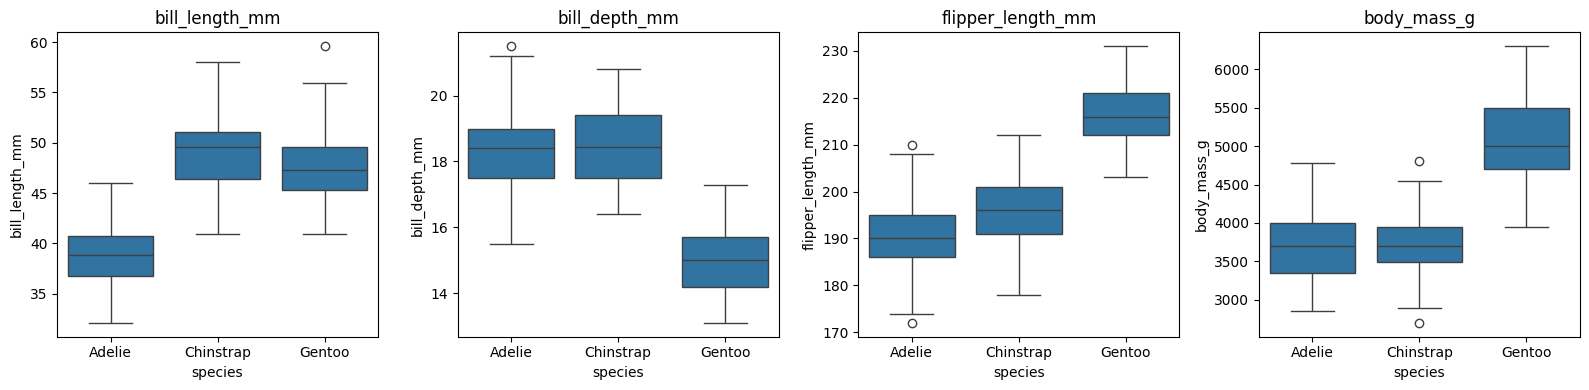

In [ ]:
import seaborn as sns

features = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

for ax, feat in zip(axes, features):
    sns.boxplot(data=original, x="species", y=feat, ax=ax)
    ax.set_title(feat)

plt.tight_layout()
plt.show()

**2. How does the combined classification system perform compared to using individual attributes?**

The combined classification perform significantly better than the individual attributes, scoring 0.96. 

In the table below, we show the accuracies from the individual attributes next to the combined score.

In [ ]:
rows = []
for name, cols in [(f, [f]) for f in features] + [("combined", features)]:
    pred = knn_predict(cols, k=5)
    rows.append({"attributes": name,
                 "predicted": len(pred),
                 "accuracy": round(evaluate(pred), 2)})
    
pd.DataFrame(rows)

,attributes,predicted,accuracy
0,bill_length_mm,101,0.75
1,bill_depth_mm,101,0.75
2,flipper_length_mm,101,0.76
3,body_mass_g,101,0.63
4,combined,101,0.96


**3. What is the overall accuracy of the system? Provide an error analysis.**

First thing to notice is that exercise 07.01 showed that the knn data set had 102 rows with missing species, however the knn analysis 'only' classified 101 penguins, this can possibly be explained by a row that misses both the specie and another attribute.

The table below show an overview of the errors, when the combined attributes are used, 4 penguins are classified incorrect. These are all Chinstrap that have been classified as Adelie. This correlate well with our exploration of the data in exercise 07.01, where we found that there are mulitiple overlaps between the attributes of these two species.


In [ ]:
pred = knn_predict(features, k=5)
true = original.loc[pred.index, "species"]
pd.crosstab(true, pred, rownames=[""], colnames=["predicted species ->"])

predicted species ->,Adelie,Chinstrap,Gentoo
,,,
Adelie,43,0,0
Chinstrap,4,17,0
Gentoo,0,0,37
